# Bagian 1: Konfigurasi Pipeline, Taksonomi Skill, & Preprocessing Data

**Peneliti:** Bintang Maulana (`NPM: 2313020011`) — Teknik Informatika, Universitas Nusantara PGRI Kediri  
**Cakupan Notebook:**
- **Tahap 1:** Inisialisasi konfigurasi eksperimen (`PipelineConfig`) dan skema ruang fitur ablasi (`M1`–`M5`).
- **Tahap 2:** Definisi taksonomi kanonis (`113 skill` pada `8 domain TI`) dan ekstraksi berbasis regex presisi.
- **Tahap 3:** Pembersihan lowongan kerja (`9.698` mentah $\to$ `9.690` valid), normalisasi `13` kategori peran TI, audit cakupan kuartal (*EoQ Snapshot*), dan visualisasi **Gambar 1**.

- **Dukungan Mode Filter Regional Indonesia (`2023-Q1` s.d. `2026-Q4`):** Mendukung pemuatan langsung `indonesia_it_jobs_2023_2026.csv` (`5.926` lowongan TI Indonesia valid lintas 16 kuartal berurutan setelah membuang 14 baris tahun 2022).


## 1. Konfigurasi Eksperimen (`PipelineConfig`) & Skema Fitur `M1`–`M5`


In [1]:
import os
import warnings
from pathlib import Path
from dataclasses import dataclass
from typing import List, Dict, Tuple
import pandas as pd

# Nonaktifkan inferensi ArrowStringArray otomatis pada Pandas >= 2.2 / 3.0
# untuk mencegah ArrowException (ChunkedArray.to_numpy wrapping error) pada teks deskripsi panjang
try:
    pd.options.future.infer_string = False
except Exception:
    pass

warnings.filterwarnings("ignore", message=".*X does not have valid feature names.*")
warnings.filterwarnings("ignore", message=".*IProgress not found.*")

PROJECT_ROOT = Path(os.environ.get("EMERGING_SKILLS_ROOT", Path.cwd()))
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DEFAULT_RAW_CSV = Path(
    os.environ.get(
        "THEIRSTACK_CSV_PATH",
        str(PROJECT_ROOT / "data" / "raw" / "theirstack_pure_combined_2021_2026.csv"),
    )
)
if not DEFAULT_RAW_CSV.exists():
    DEFAULT_RAW_CSV = PROJECT_ROOT / "data" / "raw" / "theirstack_pure_combined_2021_2026.csv"

@dataclass
class PipelineConfig:
    """Centralized, reproducible configuration for all pipeline stages."""

    # 1. Paths
    project_root: Path = PROJECT_ROOT
    raw_data_path: Path = DEFAULT_RAW_CSV
    processed_dir: Path = PROJECT_ROOT / "data" / "processed"
    outputs_dir: Path = PROJECT_ROOT / "outputs"
    audit_dir: Path = PROJECT_ROOT / "outputs" / "audit"
    features_dir: Path = PROJECT_ROOT / "outputs" / "features"
    predictions_dir: Path = PROJECT_ROOT / "outputs" / "predictions"
    metrics_dir: Path = PROJECT_ROOT / "outputs" / "metrics"
    lead_time_dir: Path = PROJECT_ROOT / "outputs" / "lead_time"
    figures_dir: Path = PROJECT_ROOT / "outputs" / "figures"
    models_dir: Path = PROJECT_ROOT / "models"

    # 2. Preprocessing & Filtering Parameters
    deduplicate_within_quarter: bool = True
    require_it_relevance: bool = True
    use_raw_extracted_skills_fallback_when_desc_empty: bool = True

    # 3. Temporal & Panel Parameters
    min_quarter_postings_for_complete: int = 150
    max_postings_per_company_quarter: int = 5
    min_total_skill_mentions: int = 5
    min_history_quarters: int = 2
    epsilon_share: float = 0.002

    # 4. Co-occurrence Network Parameters (M2: Context Evolution)
    min_cooccurrence_count: int = 2
    jaccard_edge_threshold: float = 0.01

    # 5. Primary Target Future Emergence Definition:
    #    Causal Pre-Evaluation Quantile-Anchored Risk Set + Anti-Mean-Reversion + Binomial SE Guard (H = 2 Quarters)
    horizon_quarters: int = 2
    target_mode: str = "causal_quantile_anchored_optimal_with_multi_regime_se_audit"
    restrict_to_risk_set: bool = True
    use_quantile_anchored_primary_rule: bool = True
    anchor_max_quarter_idx: int = 6  # = first_eval_quarter_idx (9) - H (2) - 1 -> Fold 1 Train Window (2021-Q3..2022-Q3)

    # Parameter Kuantil Kausal Utama (ditetapkan pada jendela jangkar pra-evaluasi q_idx 2..6):
    risk_set_roll4_quantile: float = 0.60      # P60(causal_roll4_share) pada jendela jangkar pra-evaluasi
    risk_set_cummax_quantile: float = 0.65     # P65(causal_cummax_share) pada jendela jangkar pra-evaluasi
    emergence_abs_gain_quantile: float = 0.65  # P65(abs_gain_ref) kandidat pada jendela jangkar pra-evaluasi
    emergence_rel_gain_quantile: float = 0.65  # P65(rel_gain_ref) kandidat pada jendela jangkar pra-evaluasi

    # Parameter Ketahanan Fluktuasi Permintaan & Daya Pisah Tingkat Skill:
    use_anti_mean_reversion_baseline: bool = False  # False pada Rezim Optimal Utama; True pada Rezim Audit Ketat SE (Tahap 5C & 6B)
    min_se_guard_multiplier: float = 0.0            # 0.0 pada Rezim Optimal Utama; diuji bertahap 0.5x, 1.0x, 1.5x, 2.0x SE (Bukti Yazdanian et al., 2022)
    require_sustained_horizon_mean: bool = False    # False pada Rezim Optimal Utama; True pada Rezim Audit Ketat SE (Tahap 5C & 6B)
    se_guard_audit_levels: Tuple[float, ...] = (0.5, 1.0, 1.5, 2.0)

    # Ambang numerik hasil proyeksi kuantil jangkar pra-evaluasi (diperbarui otomatis dari data oleh
    # fit_causal_quantile_thresholds_from_anchor() pada Tahap 5; bukan lagi angka tetap 5,0% / 7,5%):
    max_baseline_share: float = 0.04737
    max_career_cummax_share: float = 0.07938
    min_future_job_count: int = 3
    min_future_abs_share_gain: float = 0.0035
    min_future_rel_share_gain: float = 0.25
    min_future_cooc_degree: float = 0.0
    min_future_role_entropy: float = 0.0

    # 6. Walk-Forward Validation Parameters (Section 10)
    first_eval_quarter_idx: int = 9
    test_window_size: int = 2
    validation_folds_count: int = 4
    top_k_values: Tuple[int, ...] = (5, 10, 15)

    # 7. Early Warning & Lead Time Parameters (Strictly Horizon-Bounded H=2 Quarters)
    confirmation_consecutive_quarters: int = 1
    default_prob_threshold: float = 0.50

    # 8. Reproducibility & ML Hyperparameters (Section 11)
    random_seed: int = 42
    allow_numpy_scipy_fallback: bool = True

    def ensure_dirs(self) -> None:
        for d in [
            self.processed_dir,
            self.outputs_dir,
            self.audit_dir,
            self.features_dir,
            self.predictions_dir,
            self.metrics_dir,
            self.lead_time_dir,
            self.figures_dir,
            self.models_dir,
        ]:
            d.mkdir(parents=True, exist_ok=True)

# Feature Group Definitions for Ablation Study (4 Core Multi-Indicator Features on Identical Candidate Risk Set)
DEMAND_FEATURES: List[str] = [
    "qoq_growth_smoothed",
    "ema_ratio_short_long",
]

CONTEXT_FEATURES: List[str] = [
    "cooc_weighted_degree_roll4",
]

CONTEXT_SYNERGY_FEATURES: List[str] = []

ROLE_FEATURES: List[str] = [
    "role_entropy_roll4",
]

MATURITY_FEATURES: List[str] = []

ABLATION_FEATURE_SETS: Dict[str, List[str]] = {
    "M1_Demand_Only": DEMAND_FEATURES,
    "M2_Context_Only": CONTEXT_FEATURES,
    "M3_Demand_Context": DEMAND_FEATURES + CONTEXT_FEATURES + CONTEXT_SYNERGY_FEATURES,
    "M4_Demand_Context_Role": DEMAND_FEATURES + CONTEXT_FEATURES + CONTEXT_SYNERGY_FEATURES + ROLE_FEATURES,
    "M5_Full_Multi_Signal": DEMAND_FEATURES + CONTEXT_FEATURES + CONTEXT_SYNERGY_FEATURES + ROLE_FEATURES + MATURITY_FEATURES,
}
import matplotlib.pyplot as plt
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

# Otomatis cari lokasi berkas CSV TheirStack jika dijalankan di direktori lokal (mis. folder scraping/ atau project root)
cfg = PipelineConfig()
if not cfg.raw_data_path.exists():
    for candidate_csv in [
        Path.cwd() / "theirstack_pure_combined_2021_2026.csv",
        Path.cwd() / "data" / "raw" / "theirstack_pure_combined_2021_2026.csv",
        Path.cwd().parent / "theirstack_pure_combined_2021_2026.csv",
        Path.cwd().parent / "data" / "raw" / "theirstack_pure_combined_2021_2026.csv",
    ]:
        if candidate_csv.exists():
            cfg.raw_data_path = candidate_csv
            break
    else:
        found_csvs = list(Path.cwd().rglob("theirstack_pure_combined_2021_2026.csv"))
        if found_csvs:
            cfg.raw_data_path = found_csvs[0]

cfg.ensure_dirs()
print("Konfigurasi berhasil diinisialisasi!")
print(f"Lokasi dataset CSV: {cfg.raw_data_path}")
print(
    f"Rezim Target Utama: {cfg.target_mode} "
    f"(Aturan Kuantil Jangkar Pra-Evaluasi q_idx<={cfg.anchor_max_quarter_idx}: "
    f"roll4<=P{int(cfg.risk_set_roll4_quantile*100)} [{cfg.max_baseline_share*100:.2f}%], "
    f"cummax<=P{int(cfg.risk_set_cummax_quantile*100)} [{cfg.max_career_cummax_share*100:.2f}%], "
    f"anti_mean_reversion={cfg.use_anti_mean_reversion_baseline}, "
    f"se_guard>={cfg.min_se_guard_multiplier:.1f}xSE, "
    f"sustained_2Q={cfg.require_sustained_horizon_mean})"
)
for k, v in ABLATION_FEATURE_SETS.items():
    print(f"  - {k:<24}: {len(v):>2} fitur")


Konfigurasi berhasil diinisialisasi!
Lokasi dataset CSV: /working_dir/c_737f7e1050a04bfb/user_uploaded_files/ttl=63d/user_uploaded/theirstack_pure_combined_2021_2026.csv
Rezim Target Utama: causal_quantile_anchored_optimal_with_multi_regime_se_audit (Aturan Kuantil Jangkar Pra-Evaluasi q_idx<=6: roll4<=P60 [4.74%], cummax<=P65 [7.94%], anti_mean_reversion=False, se_guard>=0.0xSE, sustained_2Q=False)
  - M1_Demand_Only          :  3 fitur
  - M2_Context_Only         :  3 fitur
  - M3_Demand_Context       :  6 fitur
  - M4_Demand_Context_Role  :  8 fitur
  - M5_Full_Multi_Signal    : 10 fitur


## 2. Taksonomi Skill Kanonis (113 Skill, 8 Domain) & Ekstraktor Regex


In [2]:
import re
from typing import Dict, List, Tuple, Pattern

# Structure: canonical_skill -> (domain_category, regex_pattern_string, alias_list, audit_note)
RAW_TAXONOMY_DEFINITIONS: Dict[str, Tuple[str, str, List[str], str]] = {
    # -------------------------------------------------------------------------
    # 1. PROGRAMMING LANGUAGES
    # -------------------------------------------------------------------------
    "Python": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])python(?:\s*[23](?:\.[0-9]+)?)?(?![a-zA-Z0-9_])",
        ["python", "python3", "python 3"],
        "Matched via exact token boundary.",
    ),
    "Java": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])(?:java(?:\s*(?:8|11|17|21|ee|se))?|j2ee|jvm)(?![a-zA-Z0-9_]|script)",
        ["java", "java 8", "java 11", "java 17", "j2ee", "jvm"],
        "Negative lookahead prevents matching 'JavaScript'.",
    ),
    "JavaScript": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])(?:javascript|ecmascript|es6\+?|es2015\+?|vanilla\s+js|js\s+framework\w*)(?![a-zA-Z0-9_])",
        ["javascript", "ecmascript", "es6", "es2015", "vanilla js"],
        "Separated from TypeScript and Node.js.",
    ),
    "TypeScript": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])typescript(?![a-zA-Z0-9_])",
        ["typescript"],
        "Matched as distinct statically-typed superset of JS.",
    ),
    "C++": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])c\+\+(?:\s*(?:11|14|17|20))?(?![a-zA-Z0-9_+])",
        ["c++", "c++11", "c++14", "c++17", "c++20"],
        "Custom non-word lookaround handles '+' symbols where \\b fails.",
    ),
    "C#": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])(?:c#|c-sharp)(?![a-zA-Z0-9_#])",
        ["c#", "c-sharp"],
        "Custom non-word lookaround handles '#' symbol where \\b fails. Kept distinct from .NET.",
    ),
    "Golang": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])(?:golang|go\s+language|go\s+programming|(?:written|coding|developing|proficiency|experience|fluent)\s+in\s+go\b|\bgo\s*(?:/|,|\band\b|\bor\b)\s*(?:python|rust|java|c\+\+|kotlin|ruby|scala)|(?:python|rust|java|c\+\+)\s*(?:/|,|\band\b|\bor\b)\s*go\b)(?![a-zA-Z0-9_])",
        ["golang", "go language", "go programming"],
        "Disambiguated from English verb 'go' via programming context patterns.",
    ),
    "Rust": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])rust(?![a-zA-Z0-9_])",
        ["rust"],
        "Systems programming language Rust.",
    ),
    "Scala": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])scala(?![a-zA-Z0-9_])",
        ["scala"],
        "Matched via exact token boundary (does not match 'scalable' or 'scalability').",
    ),
    "Kotlin": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])kotlin(?![a-zA-Z0-9_])",
        ["kotlin"],
        "Matched via exact token boundary.",
    ),
    "Swift": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])(?:swift(?:\s*[45])?|swiftui|rxswift)(?!\s+pace|\s+action|\s+resolution|\s+interaction)(?![a-zA-Z0-9_])",
        ["swift", "swift 5", "swiftui", "rxswift"],
        "Excludes English adjective phrases like 'swift interaction' or 'swift resolution'.",
    ),
    "PHP": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])php(?:\s*[78](?:\.[0-9]+)?)?(?![a-zA-Z0-9_])",
        ["php", "php7", "php8"],
        "Matched via exact token boundary.",
    ),
    "Ruby": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])ruby(?!\s+on\s+rails)(?![a-zA-Z0-9_])",
        ["ruby"],
        "Kept distinct from Ruby on Rails framework via negative lookahead.",
    ),
    "R": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])(?:r\s+programming|r\s+language|rstudio|tidyverse|ggplot2|(?:python|sql|sas|stata)\s*(?:,|/|\band\b|\bor\b)\s*r\b|\br\s*(?:,|/|\band\b|\bor\b)\s*(?:python|sql|sas|stata))(?![a-zA-Z0-9_])",
        ["r programming", "r language", "rstudio", "tidyverse", "ggplot2"],
        "Context-guarded to prevent matching 'R&D' or single-letter abbreviations.",
    ),
    "Bash / Shell": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])(?:bash|shell\s+script\w*|zsh|powershell)(?![a-zA-Z0-9_])",
        ["bash", "shell scripting", "zsh", "powershell"],
        "Scripting & shell automation languages.",
    ),

    # -------------------------------------------------------------------------
    # 2. WEB, BACKEND & API FRAMEWORKS
    # -------------------------------------------------------------------------
    ".NET": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:\.net(?:\s*core|\s*framework|\s*[45678](?:\.[0-9]+)?)?|asp\.net(?:\s*core|\s*mvc)?|dotnet)(?![a-zA-Z0-9_])",
        [".net", ".net core", ".net framework", "asp.net", "dotnet"],
        "Custom non-word lookbehind handles leading dot in '.NET' and keeps it separate from C#.",
    ),
    "React": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:react(?:\.js|js)?)(?!\s*[-\s]?native)(?![a-zA-Z0-9_])",
        ["react", "react.js", "reactjs"],
        "Kept distinct from React Native via negative lookahead.",
    ),
    "Angular": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:angular(?:\.js|js|\s*[0-9]+)?)(?![a-zA-Z0-9_])",
        ["angular", "angularjs", "angular 2+"],
        "Frontend framework Angular.",
    ),
    "Vue.js": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:vue(?:\.js|js|\s*[23])?|vuex|nuxt(?:\.js|js)?)(?![a-zA-Z0-9_])",
        ["vue", "vue.js", "vuejs", "vuex", "nuxt.js"],
        "Vue ecosystem.",
    ),
    "Next.js": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])next(?:\.js|js)(?![a-zA-Z0-9_])",
        ["next.js", "nextjs"],
        "Requires '.js' or 'js' suffix to never match English word 'next'.",
    ),
    "Node.js": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:node(?:\.js|js)|express(?:\.js|js)|nestjs|nest\.js)(?![a-zA-Z0-9_])",
        ["node.js", "nodejs", "express.js", "nestjs"],
        "Server-side JS runtime and frameworks.",
    ),
    "Django": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])django(?![a-zA-Z0-9_])",
        ["django", "django rest framework"],
        "Python web framework Django.",
    ),
    "FastAPI": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])fastapi(?![a-zA-Z0-9_])",
        ["fastapi"],
        "Modern async Python API framework.",
    ),
    "Flask": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])flask(?![a-zA-Z0-9_])",
        ["flask"],
        "Python micro-framework Flask.",
    ),
    "Spring Boot": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:spring\s*boot|spring\s+framework|spring\s+cloud|spring\s+mvc|spring\s+security)(?![a-zA-Z0-9_])",
        ["spring boot", "springboot", "spring framework", "spring cloud", "spring mvc"],
        "Requires 'boot/framework/cloud/mvc/security' to avoid matching season 'spring'.",
    ),
    "Ruby on Rails": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:ruby\s+on\s+rails|rails\s+framework|\bror\b)(?![a-zA-Z0-9_])",
        ["ruby on rails", "rails framework", "ror"],
        "Kept distinct from standalone Ruby language.",
    ),
    "Laravel": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])laravel(?![a-zA-Z0-9_])",
        ["laravel"],
        "PHP web framework Laravel.",
    ),
    "Tailwind CSS": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:tailwind\s*css|tailwindcss)(?![a-zA-Z0-9_])",
        ["tailwind css", "tailwindcss"],
        "Utility-first CSS framework.",
    ),
    "GraphQL": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:graphql|graph\s+ql|apollo\s+graphql)(?![a-zA-Z0-9_])",
        ["graphql", "graph ql", "apollo graphql"],
        "API query language GraphQL.",
    ),
    "REST API": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:rest(?:ful)?\s+api\w*|restful\s+(?:web\s+)?services|rest\s+web\s+services|openapi|swagger)(?![a-zA-Z0-9_])",
        ["rest api", "restful api", "restful services", "openapi", "swagger"],
        "Requires API/service context to avoid matching English word 'rest'.",
    ),
    "gRPC": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:grpc|protobuf|protocol\s+buffers)(?![a-zA-Z0-9_])",
        ["grpc", "protobuf", "protocol buffers"],
        "High-performance RPC framework.",
    ),
    "Microservices": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:microservice\w*|micro-service\w*)(?![a-zA-Z0-9_])",
        ["microservices", "microservice", "micro-services"],
        "Microservices architecture.",
    ),

    # -------------------------------------------------------------------------
    # 3. MOBILE & CROSS-PLATFORM
    # -------------------------------------------------------------------------
    "iOS": (
        "Mobile & Cross-Platform",
        r"(?<![a-zA-Z0-9_])(?:ios|xcode|cocoapods|objective-c)(?![a-zA-Z0-9_])",
        ["ios", "xcode", "cocoapods", "objective-c"],
        "Apple mobile ecosystem.",
    ),
    "Android": (
        "Mobile & Cross-Platform",
        r"(?<![a-zA-Z0-9_])(?:android(?:\s+sdk|\s+studio|\s+jetpack|\s+ndk)?)(?![a-zA-Z0-9_])",
        ["android", "android sdk", "android studio", "android jetpack"],
        "Android mobile ecosystem.",
    ),
    "React Native": (
        "Mobile & Cross-Platform",
        r"(?<![a-zA-Z0-9_])react[\s-]+native(?![a-zA-Z0-9_])",
        ["react native", "react-native"],
        "Kept distinct from web React.",
    ),
    "Flutter": (
        "Mobile & Cross-Platform",
        r"(?<![a-zA-Z0-9_])flutter(?![a-zA-Z0-9_])",
        ["flutter"],
        "Cross-platform UI toolkit Flutter.",
    ),

    # -------------------------------------------------------------------------
    # 4. DATABASES & DATA WAREHOUSES (Strictly Separated!)
    # -------------------------------------------------------------------------
    "SQL": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:sql|t-sql|pl/sql|ansi\s+sql)(?![a-zA-Z0-9_])",
        ["sql", "t-sql", "pl/sql"],
        "Matches standalone SQL/T-SQL/PL-SQL; does NOT auto-trigger on PostgreSQL/MySQL/SQLite/NoSQL.",
    ),
    "PostgreSQL": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:postgresql|postgres|postgis)(?![a-zA-Z0-9_])",
        ["postgresql", "postgres", "postgis"],
        "Kept strictly separate from generic SQL, MySQL, and SQLite.",
    ),
    "MySQL": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:mysql|mariadb)(?![a-zA-Z0-9_])",
        ["mysql", "mariadb"],
        "Kept strictly separate from generic SQL, PostgreSQL, and SQLite.",
    ),
    "SQLite": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])sqlite(?:3)?(?![a-zA-Z0-9_])",
        ["sqlite", "sqlite3"],
        "Kept strictly separate from generic SQL, PostgreSQL, and MySQL.",
    ),
    "SQL Server": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:sql\s+server|mssql|ms-sql|ssrs|ssis|ssas)(?![a-zA-Z0-9_])",
        ["sql server", "mssql", "ms-sql", "ssis", "ssrs", "ssas"],
        "Microsoft SQL Server ecosystem.",
    ),
    "Oracle DB": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:oracle\s+database|oracle\s+db|oracle\s+rdbms|oracle\s+(?:11g|12c|19c))(?![a-zA-Z0-9_])",
        ["oracle database", "oracle db", "oracle 12c", "oracle 19c"],
        "Contextualized to Oracle Database rather than company name alone.",
    ),
    "MongoDB": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])mongodb(?![a-zA-Z0-9_])",
        ["mongodb"],
        "Document NoSQL database MongoDB.",
    ),
    "Redis": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])redis(?![a-zA-Z0-9_])",
        ["redis"],
        "In-memory data store Redis.",
    ),
    "Elasticsearch": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:elasticsearch|elastic\s+search|opensearch|elk\s+stack)(?![a-zA-Z0-9_])",
        ["elasticsearch", "elastic search", "opensearch", "elk stack"],
        "Search & analytics engine.",
    ),
    "Cassandra": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:apache\s+cassandra|cassandra)(?![a-zA-Z0-9_])",
        ["cassandra", "apache cassandra"],
        "Wide-column store Cassandra.",
    ),
    "DynamoDB": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])dynamodb(?![a-zA-Z0-9_])",
        ["dynamodb", "aws dynamodb"],
        "Managed NoSQL database DynamoDB.",
    ),
    "Snowflake": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])snowflake(?!\s+schema)(?![a-zA-Z0-9_])",
        ["snowflake"],
        "Cloud data warehouse Snowflake (excludes 'snowflake schema' modeling term).",
    ),
    "BigQuery": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:bigquery|big\s+query)(?![a-zA-Z0-9_])",
        ["bigquery", "big query"],
        "GCP serverless data warehouse BigQuery.",
    ),
    "Redshift": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])redshift(?![a-zA-Z0-9_])",
        ["redshift", "aws redshift"],
        "AWS cloud data warehouse Redshift.",
    ),
    "Databricks": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:databricks|delta\s+lake)(?![a-zA-Z0-9_])",
        ["databricks", "delta lake"],
        "Lakehouse platform Databricks.",
    ),
    "Vector Database": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:vector\s+database\w*|vector\s+db\w*|vector\s+store\w*|vector\s+search|pinecone|weaviate|milvus|qdrant|chromadb|pgvector|faiss)(?![a-zA-Z0-9_])",
        ["vector database", "vector db", "vector store", "pinecone", "weaviate", "milvus", "qdrant", "chromadb", "pgvector", "faiss"],
        "Vector databases & similarity search engines for embeddings/RAG.",
    ),

    # -------------------------------------------------------------------------
    # 5. DATA ENGINEERING, BIG DATA & BI (Power BI vs Tableau vs Looker Separated!)
    # -------------------------------------------------------------------------
    "Data Engineering": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:data\s+engineering|data\s+pipeline\w*|etl\s+pipeline\w*|\betl\b|\belt\b)(?![a-zA-Z0-9_])",
        ["data engineering", "data pipelines", "etl", "elt"],
        "Data pipeline & ETL/ELT engineering.",
    ),
    "Data Governance": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:data\s+governance|data\s+catalog\w*|data\s+lineage|collibra|alation)(?![a-zA-Z0-9_])",
        ["data governance", "data catalog", "data lineage", "collibra", "alation"],
        "Enterprise data governance and lineage.",
    ),
    "Spark": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:apache\s+spark|\bspark\b(?:\s+sql|\s+streaming|\s+mllib)?)(?!\s+your\s+interest)(?![a-zA-Z0-9_])",
        ["spark", "apache spark", "spark sql", "spark streaming"],
        "Kept distinct from PySpark.",
    ),
    "PySpark": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])pyspark(?![a-zA-Z0-9_])",
        ["pyspark"],
        "Python API for Apache Spark.",
    ),
    "Hadoop": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:hadoop|hdfs|mapreduce)(?![a-zA-Z0-9_])",
        ["hadoop", "hdfs", "mapreduce"],
        "Apache Hadoop ecosystem.",
    ),
    "Hive": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:apache\s+hive|\bhive\b)(?![a-zA-Z0-9_])",
        ["hive", "apache hive"],
        "Apache Hive data warehouse.",
    ),
    "Kafka": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:apache\s+kafka|\bkafka\b)(?![a-zA-Z0-9_])",
        ["kafka", "apache kafka"],
        "Distributed event streaming platform Kafka.",
    ),
    "Flink": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:apache\s+flink|\bflink\b)(?![a-zA-Z0-9_])",
        ["flink", "apache flink"],
        "Stateful stream processing framework Apache Flink.",
    ),
    "Airflow": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:apache\s+airflow|\bairflow\b)(?![a-zA-Z0-9_])",
        ["airflow", "apache airflow"],
        "Workflow orchestration platform Airflow.",
    ),
    "dbt": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:dbt|data\s+build\s+tool)(?![a-zA-Z0-9_])",
        ["dbt", "data build tool"],
        "Analytics engineering transformation tool dbt.",
    ),
    "Power BI": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:power\s*bi|dax\s+queries)(?![a-zA-Z0-9_])",
        ["power bi", "powerbi"],
        "Strictly separated from Tableau and Looker!",
    ),
    "Tableau": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])tableau(?![a-zA-Z0-9_])",
        ["tableau"],
        "Strictly separated from Power BI and Looker!",
    ),
    "Looker": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:looker|lookml)(?![a-zA-Z0-9_])",
        ["looker", "lookml"],
        "Strictly separated from Power BI and Tableau!",
    ),
    "Pandas": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:pandas|geopandas)(?![a-zA-Z0-9_])",
        ["pandas", "geopandas"],
        "Python tabular analysis library Pandas.",
    ),
    "NumPy": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])numpy(?![a-zA-Z0-9_])",
        ["numpy"],
        "Python numerical array library NumPy.",
    ),

    # -------------------------------------------------------------------------
    # 6. CLOUD, DEVOPS, OBSERVABILITY & VERSION CONTROL (Git/GitHub/GitLab Separated!)
    # -------------------------------------------------------------------------
    "AWS": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:aws|amazon\s+web\s+services)(?![a-zA-Z0-9_])",
        ["aws", "amazon web services"],
        "Amazon Web Services cloud.",
    ),
    "Azure": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:azure|microsoft\s+azure)(?![a-zA-Z0-9_])",
        ["azure", "microsoft azure"],
        "Microsoft Azure cloud.",
    ),
    "GCP": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:gcp|google\s+cloud(?:\s+platform)?)(?![a-zA-Z0-9_])",
        ["gcp", "google cloud", "google cloud platform"],
        "Google Cloud Platform.",
    ),
    "Serverless": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:serverless|aws\s+lambda|cloud\s+functions|azure\s+functions)(?![a-zA-Z0-9_])",
        ["serverless", "aws lambda", "cloud functions", "azure functions"],
        "Serverless compute paradigm.",
    ),
    "Docker": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:docker|dockerfile|docker-compose)(?![a-zA-Z0-9_])",
        ["docker", "dockerfile", "docker-compose"],
        "Container runtime Docker.",
    ),
    "Kubernetes": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:kubernetes|k8s|eks|gke|aks|helm\s+chart\w*)(?![a-zA-Z0-9_])",
        ["kubernetes", "k8s", "eks", "gke", "aks", "helm charts"],
        "Container orchestration Kubernetes.",
    ),
    "Containerization": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:containerization|containerisation|containerized|container\s+orchestration)(?![a-zA-Z0-9_])",
        ["containerization", "containerized", "container orchestration"],
        "Containerization concepts.",
    ),
    "Terraform": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:terraform|terragrunt)(?![a-zA-Z0-9_])",
        ["terraform", "terragrunt"],
        "HashiCorp Terraform IaC tool.",
    ),
    "IaC": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:infrastructure\s+as\s+a?\s*code|infrastructure-as-code|\biac\b|\biaac\b|cloudformation|pulumi)(?![a-zA-Z0-9_])",
        ["infrastructure as code", "iac", "cloudformation", "pulumi"],
        "Infrastructure as Code paradigm & tools.",
    ),
    "Ansible": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])ansible(?![a-zA-Z0-9_])",
        ["ansible"],
        "Configuration management Ansible.",
    ),
    "CI/CD": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:ci/cd|ci\s*/\s*cd|cicd|continuous\s+integration|continuous\s+delivery|continuous\s+deployment|jenkins|circleci|teamcity|bamboo)(?![a-zA-Z0-9_])",
        ["ci/cd", "cicd", "continuous integration", "continuous delivery", "jenkins", "circleci"],
        "CI/CD automation pipelines.",
    ),
    "GitOps": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:gitops|argocd|argo\s+cd|fluxcd)(?![a-zA-Z0-9_])",
        ["gitops", "argocd", "argo cd", "fluxcd"],
        "Declarative GitOps continuous delivery.",
    ),
    "Prometheus": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:prometheus|promql)(?![a-zA-Z0-9_])",
        ["prometheus", "promql"],
        "Time-series monitoring Prometheus.",
    ),
    "Grafana": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])grafana(?![a-zA-Z0-9_])",
        ["grafana"],
        "Observability dashboarding Grafana.",
    ),
    "Datadog": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])datadog(?![a-zA-Z0-9_])",
        ["datadog"],
        "Cloud monitoring platform Datadog.",
    ),
    "Observability": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:observability|opentelemetry|open\s+telemetry)(?![a-zA-Z0-9_])",
        ["observability", "opentelemetry", "open telemetry"],
        "System observability & telemetry.",
    ),
    "Linux": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:linux|ubuntu|redhat|rhel|centos|debian|unix)(?![a-zA-Z0-9_])",
        ["linux", "ubuntu", "redhat", "rhel", "centos", "debian", "unix"],
        "Linux/Unix operating systems.",
    ),
    "Git": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:git|gitflow)(?![a-zA-Z0-9_])",
        ["git", "gitflow"],
        "Strictly separated from GitHub and GitLab via exact token boundary!",
    ),
    "GitHub": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:github|github\s+actions)(?![a-zA-Z0-9_])",
        ["github", "github actions"],
        "Strictly separated from standalone Git and GitLab!",
    ),
    "GitLab": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:gitlab|gitlab\s+ci)(?![a-zA-Z0-9_])",
        ["gitlab", "gitlab ci"],
        "Strictly separated from standalone Git and GitHub!",
    ),
    "Selenium": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])selenium(?![a-zA-Z0-9_])",
        ["selenium", "selenium webdriver"],
        "Browser test automation Selenium.",
    ),
    "Cypress": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])cypress(?![a-zA-Z0-9_])",
        ["cypress"],
        "Modern web E2E testing framework Cypress.",
    ),
    "Playwright": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])playwright(?![a-zA-Z0-9_])",
        ["playwright"],
        "Modern browser testing & automation framework Playwright.",
    ),

    # -------------------------------------------------------------------------
    # 7. AI, MACHINE LEARNING, DEEP LEARNING & GENERATIVE AI
    # -------------------------------------------------------------------------
    "Data Science": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])data\s+scien(?:ce|tist\w*)(?![a-zA-Z0-9_])",
        ["data science", "data scientist"],
        "Data science discipline.",
    ),
    "Machine Learning": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])machine\s+learning(?![a-zA-Z0-9_])",
        ["machine learning"],
        "Machine learning discipline.",
    ),
    "Deep Learning": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:deep\s+learning|neural\s+network\w*|cnn\w*|rnn\w*|lstm\w*)(?![a-zA-Z0-9_])",
        ["deep learning", "neural networks", "cnn", "rnn", "lstm"],
        "Deep neural network architectures.",
    ),
    "TensorFlow": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])tensorflow(?![a-zA-Z0-9_])",
        ["tensorflow"],
        "Kept strictly separate from Keras and PyTorch.",
    ),
    "Keras": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])keras(?![a-zA-Z0-9_])",
        ["keras"],
        "Kept strictly separate from TensorFlow.",
    ),
    "PyTorch": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])pytorch(?![a-zA-Z0-9_])",
        ["pytorch"],
        "Deep learning framework PyTorch.",
    ),
    "Scikit-Learn": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:scikit-learn|scikit\s+learn|sklearn)(?![a-zA-Z0-9_])",
        ["scikit-learn", "scikit learn", "sklearn"],
        "Classical ML library Scikit-Learn.",
    ),
    "NLP": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:natural\s+language\s+processing|\bnlp\b|spacy|nltk)(?![a-zA-Z0-9_])",
        ["nlp", "natural language processing", "spacy", "nltk"],
        "Natural Language Processing.",
    ),
    "Computer Vision": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:computer\s+vision|opencv|object\s+detection|image\s+segmentation)(?![a-zA-Z0-9_])",
        ["computer vision", "opencv", "object detection"],
        "Computer Vision & OpenCV.",
    ),
    "MLOps": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:mlops|ml\s+ops|mlflow|kubeflow|sagemaker|vertex\s+ai)(?![a-zA-Z0-9_])",
        ["mlops", "ml ops", "mlflow", "kubeflow", "sagemaker", "vertex ai"],
        "Machine Learning Operations & model lifecycle platforms.",
    ),
    "LLM": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:large\s+language\s+model\w*|\bllms?\b|gpt-?[34]\w*|chatgpt|openai\s+api|claude|llama\s*[23]?|mistral)(?![a-zA-Z0-9_])",
        ["llm", "llms", "large language models", "gpt-4", "openai api", "llama", "claude", "mistral"],
        "Large Language Models.",
    ),
    "Generative AI": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:generative\s+ai|genai|gen\s+ai|foundation\s+model\w*|diffusion\s+model\w*|stable\s+diffusion)(?![a-zA-Z0-9_])",
        ["generative ai", "genai", "gen ai", "foundation models", "diffusion models"],
        "Generative AI systems & foundation models.",
    ),
    "RAG": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:retrieval[\s-]+augmented[\s-]+generation|\brag\b)(?![a-zA-Z0-9_])",
        ["retrieval-augmented generation", "retrieval augmented generation", "rag pipeline", "rag"],
        "Context-guarded so 'RAG' (Red-Amber-Green status reporting) is never misclassified as AI RAG!",
    ),
    "AI Agents": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:ai\s+agents?|agentic\s+(?:ai|workflow\w*|system\w*)|multi-agent\s+system\w*|autogen|crewai|langgraph)(?![a-zA-Z0-9_])",
        ["ai agents", "agentic ai", "agentic workflows", "multi-agent", "autogen", "crewai", "langgraph"],
        "Autonomous AI Agents & multi-agent frameworks.",
    ),
    "LangChain": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:langchain|langsmith)(?![a-zA-Z0-9_])",
        ["langchain", "langsmith"],
        "LLM orchestration framework LangChain.",
    ),
    "LlamaIndex": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:llamaindex|llama[\s_-]*index)(?![a-zA-Z0-9_])",
        ["llamaindex", "llama-index"],
        "Data framework for LLM applications LlamaIndex.",
    ),
    "Prompt Engineering": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:prompt\s+engineering|prompt\s+design|prompt\s+tuning|few-shot\s+prompting|chain-of-thought)(?![a-zA-Z0-9_])",
        ["prompt engineering", "prompt design", "prompt tuning", "chain-of-thought"],
        "Prompt engineering & optimization.",
    ),
    "Fine-Tuning": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:fine[\s-]+tun(?:ing|ed)|peft|\blora\b|qlora|rlhf|instruction\s+tuning)(?![a-zA-Z0-9_])",
        ["fine-tuning", "fine tuning", "peft", "lora", "qlora", "rlhf"],
        "Model fine-tuning & parameter-efficient adaptation.",
    ),
    "Transformers": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:transformer\s+model\w*|transformer\s+architecture|\btransformers\b|\bbert\b|attention\s+mechanism)(?![a-zA-Z0-9_])",
        ["transformers", "transformer models", "bert", "attention mechanism"],
        "Transformer neural architectures.",
    ),
    "Hugging Face": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:hugging\s*face)(?![a-zA-Z0-9_])",
        ["huggingface", "hugging face"],
        "Hugging Face ecosystem.",
    ),
    "vLLM": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])vllm(?![a-zA-Z0-9_])",
        ["vllm"],
        "High-throughput LLM serving engine vLLM.",
    ),
    "CUDA": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:cuda|tensorrt|triton\s+inference|gpgpu)(?![a-zA-Z0-9_])",
        ["cuda", "tensorrt", "gpgpu"],
        "GPU parallel computing & inference acceleration.",
    ),

    # -------------------------------------------------------------------------
    # 8. SECURITY (Strictly Contextualized — Rejects Generic 'Security')
    # -------------------------------------------------------------------------
    "Cybersecurity": (
        "Security",
        r"(?<![a-zA-Z0-9_])(?:cyber\s*security|cybersecurity|information\s+security|infosec|application\s+security|appsec|devsecops|secops|network\s+security|cloud\s+security|penetration\s+test\w*|pentest\w*|vulnerability\s+(?:assessment|management|scanning)|siem|soc\s+analyst|owasp|cissp|iso\s*27001|nist\s+(?:csf|800)|zero\s+trust|incident\s+response|threat\s+(?:hunting|intelligence|modeling)|cryptography|encryption|iam\s+security)(?![a-zA-Z0-9_])",
        [
            "cybersecurity", "cyber security", "information security", "infosec",
            "application security", "appsec", "devsecops", "network security",
            "cloud security", "penetration testing", "siem", "owasp", "cissp",
            "iso 27001", "zero trust", "threat modeling", "incident response",
        ],
        "Requires explicit technical security context; never matches standalone 'security' (job/social/financial security).",
    ),
}

# Pre-compile regex patterns for fast, deterministic execution
COMPILED_TAXONOMY: Dict[str, Tuple[str, Pattern, List[str], str]] = {
    skill: (cat, re.compile(pat, flags=re.IGNORECASE), aliases, note)
    for skill, (cat, pat, aliases, note) in RAW_TAXONOMY_DEFINITIONS.items()
}

def get_taxonomy_dataframe():
    """Return a clean DataFrame documenting all canonical skills, categories, aliases, regexes, and audit notes."""
    import pandas as pd
    rows = []
    for skill, (cat, pat, aliases, note) in RAW_TAXONOMY_DEFINITIONS.items():
        rows.append({
            "canonical_skill": skill,
            "domain_category": cat,
            "aliases_supported": ", ".join(aliases),
            "regex_pattern": pat,
            "audit_rule_note": note,
        })
    return pd.DataFrame(rows)

from typing import Dict, List, Set, Tuple
import pandas as pd
import numpy as np

try:
    pd.options.future.infer_string = False
except Exception:
    pass

# Raw tags in `extracted_skills` that cannot be trusted without text verification
UNTRUSTED_RAW_TAGS_WITHOUT_TEXT = {"Cybersecurity"}

def _to_clean_str_list(series: pd.Series, fill_value: str = "") -> List[str]:
    """
    Safely convert any Pandas Series (including PyArrow ArrowStringArray in Pandas 2.2+/3.0+)
    into a plain Python list[str] via .tolist() without invoking ArrowExtensionArray.to_numpy(),
    preventing PyArrow C++ 'ArrowException: Unknown error: Wrapping ... failed' on long texts.
    """
    if series is None or len(series) == 0:
        return []
    raw_vals = series.tolist()
    cleaned: List[str] = []
    for val in raw_vals:
        if val is None or val is pd.NA or (isinstance(val, float) and np.isnan(val)):
            cleaned.append(fill_value)
        elif isinstance(val, str):
            cleaned.append(val.encode("utf-8", errors="replace").decode("utf-8", errors="replace"))
        else:
            cleaned.append(str(val).encode("utf-8", errors="replace").decode("utf-8", errors="replace"))
    return cleaned

def _to_clean_object_series(series: pd.Series, fill_value: str = "") -> pd.Series:
    """Return a standard Python object-dtype string Series immune to PyArrow string wrapping errors."""
    return pd.Series(_to_clean_str_list(series, fill_value=fill_value), index=series.index, dtype=object)

def extract_skills_from_text(text: str) -> List[Tuple[str, str, str]]:
    """
    Extract canonical skills and their matched surface strings from a single text string.

    Parameters
    ----------
    text : str
        Combined job title and description text.

    Returns
    -------
    List[Tuple[str, str, str]]
        List of (canonical_skill, domain_category, matched_surface_term) tuples.
    """
    if not isinstance(text, str) or not text.strip():
        return []

    found: List[Tuple[str, str, str]] = []
    for skill, (cat, compiled_pat, _, _) in COMPILED_TAXONOMY.items():
        m = compiled_pat.search(text)
        if m:
            found.append((skill, cat, m.group(0).strip()))
    return found

def normalize_skill_alias(raw_name: str) -> str:
    """
    Normalize a raw skill or alias string into its canonical skill entity name.
    Returns empty string if not recognized in the taxonomy.
    """
    if not isinstance(raw_name, str) or not raw_name.strip():
        return ""
    cleaned = raw_name.strip()
    # Direct canonical match (case-insensitive)
    for canonical in RAW_TAXONOMY_DEFINITIONS:
        if cleaned.lower() == canonical.lower():
            return canonical
    # Alias list match
    for canonical, (_, _, aliases, _) in RAW_TAXONOMY_DEFINITIONS.items():
        if cleaned.lower() in [a.lower() for a in aliases]:
            return canonical
    # Regex fallback on isolated token
    for canonical, (_, compiled_pat, _, _) in COMPILED_TAXONOMY.items():
        if compiled_pat.fullmatch(cleaned):
            return canonical
    return ""

def run_batch_skill_extraction(
    df: pd.DataFrame,
    use_raw_fallback_if_desc_empty: bool = True,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    Run vectorized regex extraction across all job postings in `df` and generate:
    1. `df_with_skills`: Job postings DataFrame with `canonical_skills` (list), `canonical_skills_str`, `n_skills`, and `extraction_method`.
    2. `job_skill_long_df`: Long-format provenance table `(job_id, year_quarter, canonical_role, canonical_skill, domain_category, extraction_source)`.
    3. `comparison_audit_df`: Audit table comparing raw `extracted_skills` vs audited regex extraction per skill.
    """
    out_df = df.copy()
    n_rows = len(out_df)
    title_list = _to_clean_str_list(out_df["title"], "")
    desc_list = _to_clean_str_list(out_df["description"], "")
    raw_ext = _to_clean_str_list(out_df["extracted_skills"], "")
    combined_texts = [f"{t} \n {d}" for t, d in zip(title_list, desc_list)]
    has_desc_arr = np.array([len(d.strip()) > 10 for d in desc_list], dtype=bool)

    # Boolean matrix: rows = jobs, cols = canonical skills (evaluated directly on Python str list)
    skill_names = list(COMPILED_TAXONOMY.keys())
    skill_cats = {k: v[0] for k, v in COMPILED_TAXONOMY.items()}
    match_matrix = {}

    for skill, (cat, compiled_pat, _, _) in COMPILED_TAXONOMY.items():
        search_fn = compiled_pat.search
        match_matrix[skill] = np.fromiter(
            (search_fn(txt) is not None for txt in combined_texts),
            dtype=bool,
            count=n_rows,
        )

    match_df = pd.DataFrame(match_matrix, index=out_df.index)

    # Build per-job skill lists and long provenance records
    canonical_skills_col: List[List[str]] = []
    extraction_method_col: List[str] = []
    long_records: List[Dict[str, object]] = []

    job_ids = _to_clean_str_list(out_df["job_id"], "")
    yqs = _to_clean_str_list(out_df["year_quarter"], "")
    roles = (
        _to_clean_str_list(out_df["canonical_role"], "")
        if "canonical_role" in out_df.columns
        else _to_clean_str_list(out_df["role_category"], "")
    )

    mat_values = match_df.to_numpy()
    for i in range(len(out_df)):
        row_matches = [skill_names[j] for j in np.flatnonzero(mat_values[i])]
        method = "regex_title_and_description" if has_desc_arr[i] else "regex_title_only"

        # If description is empty and no title skills matched, optionally check safe raw tags
        if not has_desc_arr[i] and use_raw_fallback_if_desc_empty and raw_ext[i].strip():
            for raw_tok in raw_ext[i].split(","):
                norm_s = normalize_skill_alias(raw_tok)
                if norm_s and norm_s not in UNTRUSTED_RAW_TAGS_WITHOUT_TEXT and norm_s not in row_matches:
                    row_matches.append(norm_s)
                    method = "regex_title_plus_safe_raw_tag"

        canonical_skills_col.append(row_matches)
        extraction_method_col.append(method)

        jid = job_ids[i]
        yq = yqs[i]
        rl = roles[i]
        for sk in row_matches:
            long_records.append({
                "job_id": jid,
                "year_quarter": yq,
                "canonical_role": rl,
                "canonical_skill": sk,
                "domain_category": skill_cats[sk],
                "extraction_source": method,
            })

    out_df["canonical_skills_list"] = canonical_skills_col
    out_df["canonical_skills"] = [", ".join(lst) for lst in canonical_skills_col]
    out_df["n_canonical_skills"] = [len(lst) for lst in canonical_skills_col]
    out_df["skill_extraction_method"] = extraction_method_col

    job_skill_long_df = pd.DataFrame(long_records)

    # Build comparison audit table between raw `extracted_skills` and audited `canonical_skills`
    raw_tokens = [
        tok.strip()
        for raw_s in _to_clean_str_list(df["extracted_skills"], "")
        if raw_s.strip()
        for tok in raw_s.split(",")
        if tok.strip()
    ]
    raw_counts = pd.Series(raw_tokens, dtype=object).value_counts() if raw_tokens else pd.Series(dtype=int)
    new_counts = job_skill_long_df["canonical_skill"].value_counts() if len(job_skill_long_df) > 0 else pd.Series(dtype=int)

    all_compared_skills = sorted(set(raw_counts.index).union(set(skill_names)))
    comp_rows = []
    for sk in all_compared_skills:
        r_cnt = int(raw_counts.get(sk, 0))
        n_cnt = int(new_counts.get(sk, 0))
        diff = n_cnt - r_cnt
        status = "Consistent"
        if r_cnt == 0 and n_cnt > 0:
            status = "Newly Separated / Recovered Entity"
        elif sk == "Cybersecurity" and diff < -500:
            status = "Cleaned Generic 'security' False Positives"
        elif sk in ("SQL", "Git", "Power BI") and diff < -100:
            status = "Decoupled Conflated Entities (Postgres/MySQL, GitHub/GitLab, Tableau)"
        elif sk in ("C++", "C#", ".NET") and diff > 200:
            status = "Fixed Special-Character Boundary Regex"
        elif abs(diff) > 50:
            status = "Refined Boundary / Alias Matching"

        comp_rows.append({
            "skill": sk,
            "domain_category": skill_cats.get(sk, "Legacy Raw Tag"),
            "raw_extracted_count": r_cnt,
            "audited_canonical_count": n_cnt,
            "count_difference": diff,
            "audit_diagnosis": status,
        })

    comparison_audit_df = pd.DataFrame(comp_rows).sort_values("audited_canonical_count", ascending=False).reset_index(drop=True)
    return out_df, job_skill_long_df, comparison_audit_df

tax_df = get_taxonomy_dataframe()
tax_df.to_csv(cfg.processed_dir / 'skill_taxonomy_and_aliases.csv', index=False)
print(f'Total skill kanonis dalam taksonomi: {len(tax_df)} skill lintas {tax_df["domain_category"].nunique()} domain TI.')
print(tax_df[["canonical_skill", "domain_category", "aliases_supported", "audit_rule_note"]].head(15).to_string(index=False))


Total skill kanonis dalam taksonomi: 113 skill lintas 8 domain TI.
canonical_skill       domain_category                                      aliases_supported                                                                        audit_rule_note
         Python Programming Languages                              python, python3, python 3                                                      Matched via exact token boundary.
           Java Programming Languages              java, java 8, java 11, java 17, j2ee, jvm                                     Negative lookahead prevents matching 'JavaScript'.
     JavaScript Programming Languages        javascript, ecmascript, es6, es2015, vanilla js                                                 Separated from TypeScript and Node.js.
     TypeScript Programming Languages                                             typescript                                   Matched as distinct statically-typed superset of JS.
            C++ Programming Langu

## 3. Fungsi Pembersihan Data, Normalisasi Peran TI, & Audit Dataset


In [3]:
import logging
from pathlib import Path
from typing import List
import pandas as pd

logger = logging.getLogger(__name__)

REQUIRED_COLUMNS: List[str] = [
    "job_id",
    "title",
    "company",
    "location",
    "description",
    "created_dt",
    "data_source",
    "job_title_normalized",
    "core_domain",
    "role_category",
    "year",
    "quarter",
    "month",
    "year_quarter",
    "year_month",
    "extracted_skills",
]

def load_raw_job_postings(csv_path: Path) -> pd.DataFrame:
    """
    Load the raw TheirStack CSV dataset and verify schema integrity.

    Parameters
    ----------
    csv_path : Path
        Path to the raw CSV file.

    Returns
    -------
    pd.DataFrame
        Loaded DataFrame with verified columns.
    """
    path = Path(csv_path)
    if not path.exists():
        raise FileNotFoundError(
            f"Berkas dataset tidak ditemukan di {path}. "
            "Pastikan path pada config.py atau variabel lingkungan THEIRSTACK_CSV_PATH sudah benar."
        )

    logger.info("Memuat dataset mentah dari %s ...", path)
    try:
        pd.options.future.infer_string = False
    except Exception:
        pass
    df = pd.read_csv(path, low_memory=False)
    # Konversi seluruh kolom teks/string ke dtype=object (Python str murni) agar bebas ArrowException
    text_cols = [
        "job_id", "title", "company", "location", "description", "created_dt",
        "data_source", "job_title_normalized", "core_domain", "role_category",
        "year_quarter", "year_month", "extracted_skills",
    ]
    for tc in text_cols:
        if tc in df.columns:
            raw_list = df[tc].tolist()
            df[tc] = pd.Series(
                [
                    np.nan if (v is None or v is pd.NA or (isinstance(v, float) and np.isnan(v)))
                    else str(v).encode("utf-8", errors="replace").decode("utf-8", errors="replace")
                    for v in raw_list
                ],
                index=df.index,
                dtype=object,
            )

    missing_cols = [c for c in REQUIRED_COLUMNS if c not in df.columns]
    if missing_cols:
        raise ValueError(
            f"Struktur kolom dataset tidak sesuai! Kolom berikut tidak ditemukan: {missing_cols}"
        )

    if len(df) == 0:
        raise ValueError("Dataset kosong (0 baris).")

    logger.info("Dataset berhasil dimuat: %d baris x %d kolom.", df.shape[0], df.shape[1])
    return df

import re
from typing import Dict, List, Tuple
import pandas as pd

UNCLASSIFIED_ROLE_LABEL = "Other / Unclassified IT Role"

# Ordered, mutually-exclusive priority rules for normalizing IT job titles into 12 explicit canonical roles.
# Unmatched titles are routed to UNCLASSIFIED_ROLE_LABEL ('Other / Unclassified IT Role').
ROLE_NORMALIZATION_RULES: List[Tuple[str, str, str]] = [
    (
        "Cybersecurity & InfoSec",
        r"\b(?:cyber\s*security|information\s+security|infosec|security\s+(?:engineer\w*|analyst\w*|architect\w*|specialist\w*|operations|compliance|consultant\w*|risk)|soc\s+analyst|security\s+ops|penetration\s+tester|pentester|devsecops|application\s+security|appsec|cloud\s+security|network\s+security|firewall\s+engineer|vulnerability)\b",
        "Explicit security / cybersecurity / DevSecOps title keywords",
    ),
    (
        "Data Scientist & AI / ML Engineer",
        r"\b(?:data\s+(?:&\s+ai\s+)?scientist\w*|machine\s+learning|ml\s+engineer\w*|ai\s+(?:[a-z]+\s+)?engineer\w*|llm\s+engineer\w*|prompt\s+engineer\w*|genai\s+engineer\w*|generative\s+ai|artificial\s+intelligence|deep\s+learning|computer\s+vision|nlp|natural\s+language|mlops|research\s+scientist|applied\s+scientist|quantitative\s+research\w*|bioinformatics)\b",
        "Explicit AI, ML, Data Science, NLP, Computer Vision, or MLOps title keywords",
    ),
    (
        "Data Engineer & Analytics Engineer",
        r"\b(?:data\s+(?:[a-z]+\s+)?engineer\w*|engineer:\s*data|analytics\s+engineer\w*|big\s+data|data\s+platform|data\s+infrastructure|data\s+warehouse|etl\s+(?:developer|engineer)|bi\s+(?:engineer|developer)|business\s+intelligence\s+(?:engineer|developer)|bi\s*\(business\s+intelligence\)\s*developer|power\s*bi\s+developer|tableau\s+developer|database\s+(?:developer|engineer)|data\s+architect|data\s+integration|data\s+modeller|data\s+modeling|snowflake\s+(?:developer|engineer)|databricks\s+(?:developer|engineer)|sql\s+develop(?:er|ment))\b",
        "Explicit Data Engineering, Data Platform, ETL, Warehouse, or Analytics Engineering title keywords",
    ),
    (
        "Data & BI Analyst",
        r"\b(?:data\s+(?:[a-z&]+\s+){0,2}analyst\w*|business\s+intelligence\s+analyst|bi\s+analyst|product\s+analyst|marketing\s+data\s+analyst|financial\s+data\s+analyst|research\s+data\s+analyst|reporting\s+analyst|analytics\s+analyst|master\s+data\s+(?:analyst|management)|business\s+analyst\s*[-–—:]?\s*.*data|data\s+science\s+business\s+systems\s+analyst|quantitative\s+analyst|decision\s+science\s+analyst)\b",
        "Explicit Data Analyst, BI Analyst, or specialized Analytics title keywords",
    ),
    (
        "DevOps, SRE & Cloud Infrastructure",
        r"\b(?:devops|site\s+reliability|sre\b|cloud\s+(?:[a-z]+\s+){0,2}(?:engineer\w*|architect\w*|operations|ops|support|infrastructure|platform|solution\w*|developer\w*)|platform\s+(?:[a-z]+\s+)?engineer\w*|infrastructure\s+(?:[a-z]+\s+)?engineer\w*|release\s+engineer\w*|build\s+(?:system\s+)?engineer\w*|kubernetes|aws\s+.*(?:engineer|developer)|azure\s+.*(?:engineer|developer)|gcp\s+.*(?:engineer|developer)|vmware\s+.*engineer|production\s+engineer|linux\s+.*engineer|ci/cd\s+engineer|terraform)\b",
        "Explicit DevOps, SRE, Cloud, Platform, or Infrastructure Engineering title keywords",
    ),
    (
        "QA & Test Automation Engineer",
        r"\b(?:qa\b|quality\s+assurance|test\s+automation|automation\s+(?:qa|test\w*)|sdet\b|software\s+development\s+engineer\s+in\s+test|software\s+engineer\s+in\s+test|test\s+(?:[a-z]+\s+)?engineer\w*|sqa\b|quality\s+(?:[a-z]+\s+)?engineer\w*|performance\s+test\w*)\b",
        "Explicit QA, SDET, or Test Automation title keywords",
    ),
    (
        "Systems, Network & Database Admin",
        r"\b(?:systems?\s+administrator|sysadmin|network\s+(?:[a-z&]+\s+){0,2}(?:engineer\w*|administrator|operations|ops|performance|specialist|analyst)|noc\s+engineer|database\s+administrator|\bdba\b|it\s+administrator|salesforce\s+administrator|sharepoint.*administrator|telephony.*administrator|citrix.*administrator|middleware.*administrator|data\s+cent(?:er|re)s?\s+(?:facilities|network|engineer|technician|operations)|field\s+data\s+centre|commissioning\s+engineer\s*\(data\s+centers\)|system\s+support\s+engineer|technical\s+support\s+engineer|it\s+support\s+engineer|desktop\s+support)\b",
        "Explicit Systems Admin, Network Engineer, NOC, or DBA title keywords",
    ),
    (
        "Solutions & Enterprise Architect",
        r"\b(?:solutions?\s+architect|enterprise\s+architect|technical\s+architect|system\s+architect|software\s+architect|information\s+architect|cloud\s+architect|it\s+architect|application\s+architect|security\s+architect)\b",
        "Explicit Solutions, Enterprise, or Technical Architect title keywords",
    ),
    (
        "Mobile Developer (iOS / Android)",
        r"\b(?:ios\b|android\b|mobile\s+(?:[a-z]+\s+)?(?:developer|engineer|app\w*|software)|react\s+native|flutter|swift\s+(?:developer|engineer)|kotlin\s+(?:developer|engineer)|xamarin)\b",
        "Explicit Mobile, iOS, Android, React Native, or Flutter title keywords",
    ),
    (
        "Frontend & Web Developer",
        r"\b(?:front[\s-]*end|frontend|ui\s+(?:developer|engineer)|ui/ux\s+(?:developer|engineer)|react(?:\.js|js)?\s+(?:[a-z]+\s+)?(?:developer|engineer)|angular(?:\.js|js)?\s+(?:developer|engineer)|vue(?:\.js|js)?\s+(?:developer|engineer)|web\s+(?:[a-z/&]+\s+){0,2}(?:developer|engineer|designer/developer)|javascript\s+(?:developer|engineer)|typescript\s+(?:developer|engineer)|wordpress|shopify|drupal|magento)\b",
        "Explicit Frontend, UI, React/Angular/Vue, or Web Developer title keywords",
    ),
    (
        "Full Stack Developer",
        r"\b(?:full[\s-]*stack|fullstack)\b",
        "Explicit Full Stack Developer / Engineer title keywords",
    ),
    (
        "Backend & Core Software Engineer",
        r"(?:(?<![a-zA-Z0-9_])\.?net\s+(?:[a-z]+\s+)?(?:developer|software|systems|engineer)|\b(?:back[\s-]*end|backend|software\s+(?:[a-z]+\s+)?(?:engineer\w*|developer\w*)|java[\s-]+(?:[a-z]+\s+){0,2}(?:developer|engineer)|python\s+(?:[a-z]+\s+)?(?:developer|engineer)|dot\s*net\s+developer|c#\s*\.?net|c#\s+(?:developer|engineer)|c\+\+\s+(?:[a-z]+\s+)?(?:developer|engineer)|golang.*(?:engineer|developer)|go\s+(?:backend|developer|engineer)|node[\s.]*js\s+(?:[a-z]+\s+)?(?:developer|engineer)|php\s+(?:[a-z]+\s+)?(?:developer|engineer)|laravel\s+developer|ruby\s+(?:on\s+rails\s+)?(?:developer|engineer)|rails\s+(?:developer|engineer)|rust\s+.*(?:engineer|developer)|scala\s+(?:developer|engineer)|spring\s+boot\s+developer|embedded\s+(?:software|systems|engineer)|firmware\s+engineer|game\s+(?:developer|engineer)|unity.*(?:developer|engineer)|unreal.*(?:developer|engineer)|audio\s+software|compute\s+software|integrations?\s+(?:engineer|developer)|application\s+(?:[a-z]+\s+)?(?:developer|engineer)|systems?\s+software\s+(?:engineer|developer)|api\s+(?:developer|engineer)|microservices?\s+(?:developer|engineer)|mainframe\s+(?:developer|engineer)|cobol\s+(?:developer|engineer)|abap\s+(?:developer|engineer)|salesforce\s+(?:developer|engineer)|servicenow\s+(?:developer|engineer)|erp\s+(?:developer|engineer)|programmer)\b)",
        "Explicit Backend, Language-Specific, Embedded, or Core Software Engineering title keywords",
    ),
]

COMPILED_ROLE_RULES: List[Tuple[str, re.Pattern, str]] = [
    (role, re.compile(pat, flags=re.IGNORECASE), desc)
    for role, pat, desc in ROLE_NORMALIZATION_RULES
]

def normalize_single_role(title: str, raw_role_category: str = "") -> Tuple[str, str]:
    """
    Normalize a single job's title into an explicit canonical role and rule explanation.
    Unrecognized or generic job titles are assigned to `Other / Unclassified IT Role`
    rather than forced into Backend or Data Engineering, avoiding spurious role expansion.
    """
    t = str(title or "").strip()
    for canonical_role, pat, rule_desc in COMPILED_ROLE_RULES:
        if pat.search(t):
            return canonical_role, rule_desc

    return (
        UNCLASSIFIED_ROLE_LABEL,
        "Unclassified / Ambiguous Job Title (Flagged as Uncertain; Excluded from Active Role Expansion)",
    )

def apply_role_normalization(df: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """
    Apply deterministic role normalization across all rows of `df`, attach explicit uncertainty flags,
    and generate an auditable mapping summary.

    Returns
    -------
    Tuple[pd.DataFrame, pd.DataFrame]
        (df_with_canonical_role, role_mapping_audit_df)
    """
    out_df = df.copy()
    titles = _to_clean_str_list(out_df["title"], "")
    raw_cats = _to_clean_str_list(out_df["role_category"], "")

    norm_results = [normalize_single_role(t, r) for t, r in zip(titles, raw_cats)]
    out_df["canonical_role"] = [res[0] for res in norm_results]
    out_df["role_mapping_rule"] = [res[1] for res in norm_results]
    out_df["is_role_classified_certain"] = out_df["canonical_role"] != UNCLASSIFIED_ROLE_LABEL
    out_df["role_uncertainty_flag"] = out_df["is_role_classified_certain"].map(
        {True: "Certain_Explicit_Title_Match", False: "Uncertain_Unclassified_Title"}
    )

    mapping_audit = (
        out_df.groupby(
            ["role_category", "canonical_role", "role_uncertainty_flag", "role_mapping_rule"],
            as_index=False,
        )
        .agg(
            job_count=("job_id", "count"),
            sample_titles=("job_title_normalized", lambda s: "; ".join(s.value_counts().head(3).index.tolist())),
        )
        .sort_values(["canonical_role", "job_count"], ascending=[True, False])
        .reset_index(drop=True)
    )
    mapping_audit["share_of_total_pct"] = (mapping_audit["job_count"] / len(out_df) * 100).round(2)
    return out_df, mapping_audit

import hashlib
import logging
import re
from typing import Dict, Tuple
import pandas as pd
import numpy as np

logger = logging.getLogger(__name__)

# Non-IT title patterns that should be excluded IF they also contain zero canonical IT skills
NON_IT_EXCLUSION_TITLE_PATTERN = re.compile(
    r"\b(?:vendor\s+master\s+data\s+analyst|qc\s+data\s+review\s+scientist|sales\s+data\s+analyst|talent\s+acquisition|account\s+executive|recruiter|human\s+resources|bookkeeper)\b",
    flags=re.IGNORECASE,
)

def clean_and_preprocess_postings(
    raw_df: pd.DataFrame,
    deduplicate_within_quarter: bool = True,
    require_it_relevance: bool = True,
    use_raw_skill_fallback: bool = True,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame, Dict[str, object]]:
    """
    Execute the complete, auditable preprocessing pipeline on raw job postings.

    Returns
    -------
    processed_df : pd.DataFrame
        Cleaned, deduplicated, IT-filtered job postings with `canonical_role` and `canonical_skills`.
    job_skill_long_df : pd.DataFrame
        Long-format table of `(job_id, year_quarter, canonical_role, canonical_skill, domain_category, extraction_source)`.
    role_mapping_df : pd.DataFrame
        Audit table of role normalization rules and counts.
    skill_comparison_df : pd.DataFrame
        Audit table comparing raw `extracted_skills` vs regex-extracted `canonical_skills`.
    cleaning_report : Dict[str, object]
        Dictionary of step-by-step record counts and cleaning statistics.
    """
    df = raw_df.copy()
    initial_rows = len(df)

    # 1. Date normalization & validation
    df["created_dt_parsed"] = pd.to_datetime(df["created_dt"], errors="coerce")
    invalid_dates = int(df["created_dt_parsed"].isna().sum())
    if invalid_dates > 0:
        logger.warning("Menghapus %d baris dengan created_dt tidak valid.", invalid_dates)
        df = df[df["created_dt_parsed"].notna()].copy()

    # Verify year, quarter, month, and year_quarter consistency with created_dt_parsed
    df["year"] = df["created_dt_parsed"].dt.year.astype(int)
    df["quarter"] = df["created_dt_parsed"].dt.quarter.astype(int)
    df["month"] = df["created_dt_parsed"].dt.month.astype(int)
    df["year_quarter"] = pd.Series(
        [f"{int(y)}-Q{int(q)}" for y, q in zip(df["year"].tolist(), df["quarter"].tolist())],
        index=df.index,
        dtype=object,
    )

    # 2. Text cleaning & missing value flags (pure Python str object series, ArrowException-safe)
    title_clean_list = [s.strip() for s in _to_clean_str_list(df["title"], "")]
    company_clean_list = [s.strip() if s.strip() else "Unknown_Company" for s in _to_clean_str_list(df["company"], "Unknown_Company")]
    location_clean_list = [s.strip() if s.strip() else "Unspecified" for s in _to_clean_str_list(df["location"], "Unspecified")]
    desc_clean_list = [s.strip() for s in _to_clean_str_list(df["description"], "")]

    df["title_clean"] = pd.Series(title_clean_list, index=df.index, dtype=object)
    df["company_clean"] = pd.Series(company_clean_list, index=df.index, dtype=object)
    df["location_clean"] = pd.Series(location_clean_list, index=df.index, dtype=object)
    df["description_clean"] = pd.Series(desc_clean_list, index=df.index, dtype=object)
    df["has_description"] = np.array([len(d) > 10 for d in desc_clean_list], dtype=bool)

    # Compute content hash for duplicate detection
    def _hash_row(row_tuple) -> str:
        t_str, c_str, d_str = row_tuple
        if len(d_str) > 50:
            norm_d = re.sub(r"\s+", " ", d_str.lower())
            return hashlib.md5(norm_d.encode("utf-8", errors="ignore")).hexdigest()
        norm_tc = f"{t_str.lower().strip()}||{c_str.lower().strip()}"
        return hashlib.md5(norm_tc.encode("utf-8", errors="ignore")).hexdigest()

    df["content_hash"] = [
        _hash_row(tup)
        for tup in zip(df["title_clean"], df["company_clean"], df["description_clean"])
    ]

    # 3. Deduplication
    exact_job_id_dups = int(df.duplicated(subset=["job_id"]).sum())
    if exact_job_id_dups > 0:
        df = df.drop_duplicates(subset=["job_id"], keep="first").copy()

    within_quarter_content_dups = int(
        df.duplicated(subset=["year_quarter", "company_clean", "title_clean", "content_hash"]).sum()
    )
    if deduplicate_within_quarter and within_quarter_content_dups > 0:
        logger.info(
            "Menghapus %d duplikasi reposting identik dalam kuartal yang sama.",
            within_quarter_content_dups,
        )
        df = df.drop_duplicates(
            subset=["year_quarter", "company_clean", "title_clean", "content_hash"],
            keep="first",
        ).copy()

    after_dedup_rows = len(df)

    # 4. Role Normalization
    df, role_mapping_df = apply_role_normalization(df)

    # 5. Skill Extraction & Normalization
    df, job_skill_long_df, skill_comparison_df = run_batch_skill_extraction(
        df, use_raw_fallback_if_desc_empty=use_raw_skill_fallback
    )

    # 6. IT Relevance Filtering
    # A posting is retained as a valid IT job posting unless it matches a known non-IT administrative/lab/sales title
    # AND has 0 extracted IT technical skills.
    non_it_search = NON_IT_EXCLUSION_TITLE_PATTERN.search
    non_it_title_match = pd.Series(
        [non_it_search(t) is not None for t in _to_clean_str_list(df["title_clean"], "")],
        index=df.index,
        dtype=bool,
    )
    zero_it_skills = df["n_canonical_skills"] == 0
    non_it_excluded_mask = non_it_title_match & zero_it_skills
    n_non_it_excluded = int(non_it_excluded_mask.sum())

    if require_it_relevance and n_non_it_excluded > 0:
        logger.info("Menyaring %d lowongan non-IT yang tidak memiliki keterampilan teknis TI.", n_non_it_excluded)
        df = df[~non_it_excluded_mask].copy()
        valid_ids = set(df["job_id"])
        job_skill_long_df = job_skill_long_df[job_skill_long_df["job_id"].isin(valid_ids)].copy()

    final_rows = len(df)
    cleaning_report: Dict[str, object] = {
        "initial_raw_rows": initial_rows,
        "invalid_date_rows_removed": invalid_dates,
        "exact_job_id_duplicates_removed": exact_job_id_dups,
        "within_quarter_repost_duplicates_removed": within_quarter_content_dups if deduplicate_within_quarter else 0,
        "rows_after_deduplication": after_dedup_rows,
        "non_it_rows_filtered": n_non_it_excluded if require_it_relevance else 0,
        "final_valid_it_postings": final_rows,
        "postings_with_full_description": int(df["has_description"].sum()),
        "postings_with_title_only": int((~df["has_description"]).sum()),
        "postings_with_at_least_1_skill": int((df["n_canonical_skills"] >= 1).sum()),
        "postings_with_0_skills_extracted": int((df["n_canonical_skills"] == 0).sum()),
        "total_job_skill_pairs_extracted": len(job_skill_long_df),
        "unique_canonical_skills_detected": int(job_skill_long_df["canonical_skill"].nunique()),
        "unique_canonical_roles": int(df["canonical_role"].nunique()),
    }

    return df, job_skill_long_df, role_mapping_df, skill_comparison_df, cleaning_report

import re
from pathlib import Path
from typing import Dict, Any, List, Tuple
import pandas as pd
import numpy as np

# Candidate technical terms outside the 113-skill canonical taxonomy for Open-Vocabulary Discovery Audit (Fix #6)
OPEN_VOCAB_CANDIDATE_PATTERNS: Dict[str, Tuple[str, str]] = {
    "Model Context Protocol (MCP)": ("AI / ML & GenAI", r"\b(?:model\s+context\s+protocol|\bmcp\s+server\w*)\b"),
    "Dagster / Prefect": ("Data & Analytics", r"\b(?:dagster|prefect)\b"),
    "ClickHouse": ("Databases & Warehouses", r"\bclickhouse\b"),
    "Svelte / SvelteKit": ("Web & Backend", r"\bsvelte(?:kit)?\b"),
    "Trino / Presto": ("Data & Analytics", r"\b(?:trino|prestodb|presto\s+sql)\b"),
    "Gradio / Streamlit": ("AI / ML & GenAI", r"\b(?:streamlit|gradio)\b"),
    "Supabase": ("Databases & Warehouses", r"\bsupabase\b"),
    "Apache Iceberg": ("Data & Analytics", r"\b(?:apache\s+iceberg|\biceberg\s+table\w*)\b"),
    "Cilium / eBPF": ("Cloud & DevOps", r"\b(?:ebpf|cilium)\b"),
    "Pydantic": ("AI / ML & GenAI", r"\bpydantic\b"),
    "Weights & Biases (WandB)": ("AI / ML & GenAI", r"\b(?:weights\s*(?:&|and)\s*biases|wandb)\b"),
    "Polars": ("Data & Analytics", r"\bpolars\b"),
    "ONNX Runtime": ("AI / ML & GenAI", r"\bonnx(?:runtime)?\b"),
    "Ollama": ("AI / ML & GenAI", r"\bollama\b"),
    "DuckDB": ("Databases & Warehouses", r"\bduckdb\b"),
}

def _calendar_days_in_quarter(year: int, quarter: int) -> int:
    if quarter == 1:
        is_leap = (year % 4 == 0 and year % 100 != 0) or (year % 400 == 0)
        return 91 if is_leap else 90
    if quarter == 2:
        return 91
    return 92

def discover_unregistered_technical_candidates(processed_df: pd.DataFrame) -> pd.DataFrame:
    """
    Scan job titles and descriptions for emerging technical terms NOT yet included in the
    113-skill canonical taxonomy, demonstrating how the closed-vocabulary panel can be
    systematically expanded via corpus surveillance (Fix #6).
    """
    t_list = _to_clean_str_list(processed_df["title"], "")
    d_list = _to_clean_str_list(processed_df["description"], "")
    comb_list = [f"{t} \n {d}" for t, d in zip(t_list, d_list)]
    n_rows_ov = len(comb_list)
    years = processed_df["year"].to_numpy()
    yqs = np.array(_to_clean_str_list(processed_df["year_quarter"], ""), dtype=object)
    n_early = max(int(np.sum(years <= 2023)), 1)
    n_late = max(int(np.sum(years >= 2024)), 1)

    rows = []
    for term_name, (dom, pat) in OPEN_VOCAB_CANDIDATE_PATTERNS.items():
        comp_ov = re.compile(pat, flags=re.IGNORECASE)
        ov_search = comp_ov.search
        matches = np.fromiter((ov_search(txt) is not None for txt in comb_list), dtype=bool, count=n_rows_ov)
        total_cnt = int(np.sum(matches))
        if total_cnt == 0:
            continue
        early_cnt = int(np.sum(matches & (years <= 2023)))
        late_cnt = int(np.sum(matches & (years >= 2024)))
        matched_yqs = sorted(set(yqs[matches]))
        rows.append({
            "unregistered_candidate_term": term_name,
            "suggested_domain": dom,
            "mentions_2021_2023": early_cnt,
            "share_2021_2023_pct": round(early_cnt / n_early * 100.0, 3),
            "mentions_2024_2026": late_cnt,
            "share_2024_2026_pct": round(late_cnt / n_late * 100.0, 3),
            "total_mentions": total_cnt,
            "first_observed_quarter": matched_yqs[0] if matched_yqs else "None",
            "latest_observed_quarter": matched_yqs[-1] if matched_yqs else "None",
            "meets_min_5_mentions_for_taxonomy_promotion": total_cnt >= 5,
            "taxonomy_status": (
                "Ready for Taxonomy Promotion (>=5 mentions)"
                if total_cnt >= 5
                else "Monitor in Candidate Watchlist (<5 mentions)"
            ),
        })
    return pd.DataFrame(rows).sort_values(["mentions_2024_2026", "total_mentions"], ascending=False).reset_index(drop=True)

def run_comprehensive_data_audit(
    raw_df: pd.DataFrame,
    processed_df: pd.DataFrame,
    job_skill_long_df: pd.DataFrame,
    role_mapping_df: pd.DataFrame,
    skill_comparison_df: pd.DataFrame,
    cleaning_report: Dict[str, Any],
    audit_dir: Path,
    min_quarter_postings: int = 150,
) -> Dict[str, pd.DataFrame]:
    """
    Generate all audit tables and save them as CSV in `audit_dir`.
    """
    audit_dir.mkdir(parents=True, exist_ok=True)

    # 1. Column Schema & Missingness Audit
    schema_rows = []
    for col in raw_df.columns:
        s = raw_df[col]
        null_cnt = int(s.isna().sum())
        s_str_list = _to_clean_str_list(s, "")
        empty_str_cnt = int(sum(1 for x in s_str_list if x.strip() == "")) - null_cnt
        total_missing = null_cnt + max(empty_str_cnt, 0)
        schema_rows.append({
            "column_name": col,
            "dtype": str(s.dtype),
            "total_rows": len(raw_df),
            "non_null_count": int(s.notna().sum()),
            "null_count": null_cnt,
            "empty_string_count": max(empty_str_cnt, 0),
            "total_missing_count": total_missing,
            "missing_pct": round(total_missing / len(raw_df) * 100, 2),
            "n_unique": int(s.nunique(dropna=True)),
            "sample_value": str(s.dropna().iloc[0])[:80] if s.notna().any() else "ALL_NULL",
        })
    schema_df = pd.DataFrame(schema_rows)
    schema_df.to_csv(audit_dir / "01_column_schema_and_missingness.csv", index=False)

    # 2. Quarterly Completeness, Date Span, & EoQ Snapshot Sampling Audit (Fix #1)
    raw_df_dt = raw_df.copy()
    raw_df_dt["created_dt_parsed"] = pd.to_datetime(raw_df_dt["created_dt"], errors="coerce")
    q_raw = raw_df_dt.groupby(["year_quarter", "year", "quarter"], as_index=False).agg(
        raw_postings=("job_id", "count"),
        raw_unique_jobs=("job_id", "nunique"),
        min_date=("created_dt_parsed", lambda s: str(s.min().date())),
        max_date=("created_dt_parsed", lambda s: str(s.max().date())),
        observed_span_days=("created_dt_parsed", lambda s: int((s.max().date() - s.min().date()).days + 1)),
        n_unique_dates=("created_dt_parsed", lambda s: int(s.dt.date.nunique())),
        months_observed=("created_dt_parsed", lambda s: ",".join(str(m) for m in sorted(s.dt.month.unique()))),
        missing_descriptions=("description", lambda s: int(sum(1 for x in _to_clean_str_list(s, "") if x.strip() == ""))),
        missing_raw_skills=("extracted_skills", lambda s: int(sum(1 for x in _to_clean_str_list(s, "") if x.strip() == ""))),
    )
    q_raw["calendar_days_in_quarter"] = [
        _calendar_days_in_quarter(int(y), int(q)) for y, q in zip(q_raw["year"], q_raw["quarter"])
    ]
    q_raw["calendar_day_coverage_pct"] = (
        q_raw["n_unique_dates"] / q_raw["calendar_days_in_quarter"].astype(float) * 100.0
    ).round(2)

    q_clean = processed_df.groupby("year_quarter", as_index=False).agg(
        clean_valid_postings=("job_id", "nunique"),
        mean_skills_per_job=("n_canonical_skills", lambda s: round(float(s.mean()), 2)),
        median_skills_per_job=("n_canonical_skills", lambda s: float(s.median())),
    )
    q_skills = job_skill_long_df.groupby("year_quarter", as_index=False).agg(
        unique_active_skills=("canonical_skill", "nunique"),
        total_skill_mentions=("canonical_skill", "count"),
    )

    quarterly_audit_df = (
        q_raw.merge(q_clean, on="year_quarter", how="left")
        .merge(q_skills, on="year_quarter", how="left")
        .sort_values("year_quarter")
        .reset_index(drop=True)
    )
    # Binomial sampling error for a typical 5% skill share at sample size N_t: SE = sqrt(0.05 * 0.95 / N_t)
    quarterly_audit_df["binomial_se_at_5pct_share"] = (
        np.sqrt(0.05 * 0.95 / quarterly_audit_df["clean_valid_postings"].astype(float)) * 100.0
    ).round(3)
    quarterly_audit_df["min_observable_share_step_pct"] = (
        100.0 / quarterly_audit_df["clean_valid_postings"].astype(float)
    ).round(3)
    quarterly_audit_df["is_complete_quarter"] = quarterly_audit_df["clean_valid_postings"] >= min_quarter_postings
    quarterly_audit_df["is_full_calendar_quarter"] = quarterly_audit_df["calendar_day_coverage_pct"] >= 50.0
    quarterly_audit_df["sampling_regime"] = np.where(
        quarterly_audit_df["calendar_day_coverage_pct"] < 15.0,
        "End-of-Quarter (EoQ) API Snapshot (Closing 1-8 Days of Mar/Jun/Sep/Dec)",
        "Multi-Week Quarterly Coverage",
    )
    quarterly_audit_df["sampling_note"] = np.where(
        quarterly_audit_df["year_quarter"] == "2021-Q1",
        "EoQ Snapshot (225 valid jobs, 2 closing days of Mar 2021; higher binomial SE=1.45%)",
        "EoQ Snapshot (~291-499 valid jobs, closing 1-8 days of quarter; binomial SE=0.98%-1.28%)",
    )
    quarterly_audit_df.to_csv(audit_dir / "02_quarterly_completeness_audit.csv", index=False)

    # 3. Role Distribution Comparison (Raw vs Normalized)
    raw_role_dist = (
        raw_df["role_category"]
        .value_counts(dropna=False)
        .rename_axis("role_name")
        .reset_index(name="job_count")
    )
    raw_role_dist["share_pct"] = (raw_role_dist["job_count"] / len(raw_df) * 100).round(2)
    raw_role_dist["source"] = "Raw (role_category == core_domain)"

    clean_role_dist = (
        processed_df["canonical_role"]
        .value_counts(dropna=False)
        .rename_axis("role_name")
        .reset_index(name="job_count")
    )
    clean_role_dist["share_pct"] = (clean_role_dist["job_count"] / len(processed_df) * 100).round(2)
    clean_role_dist["source"] = "Normalized (canonical_role)"

    role_dist_df = pd.concat([raw_role_dist, clean_role_dist], ignore_index=True)
    role_dist_df.to_csv(audit_dir / "03_role_distribution_comparison.csv", index=False)
    role_mapping_df.to_csv(audit_dir / "04_role_normalization_mapping.csv", index=False)

    # 4. Skill Extraction Audit & Comparison
    skill_comparison_df.to_csv(audit_dir / "05_skill_extraction_audit_comparison.csv", index=False)

    # 5. Cleaning Summary Table
    cleaning_summary_df = pd.DataFrame(
        [{"metric": k, "value": v} for k, v in cleaning_report.items()]
    )
    cleaning_summary_df.to_csv(audit_dir / "06_cleaning_and_deduplication_summary.csv", index=False)

    # 6. Open-Vocabulary Unregistered Technical Term Discovery (Fix #6)
    open_vocab_df = discover_unregistered_technical_candidates(processed_df)
    open_vocab_df.to_csv(audit_dir / "09_open_vocabulary_taxonomy_expansion_candidates.csv", index=False)

    return {
        "schema_df": schema_df,
        "quarterly_audit_df": quarterly_audit_df,
        "role_dist_df": role_dist_df,
        "role_mapping_df": role_mapping_df,
        "skill_comparison_df": skill_comparison_df,
        "cleaning_summary_df": cleaning_summary_df,
        "open_vocab_df": open_vocab_df,
    }


## 4. Eksekusi Preprocessing, Normalisasi Role, & Audit *EoQ Snapshot*


In [4]:
raw_df = load_raw_job_postings(cfg.raw_data_path)
processed_df, job_skill_long_df, role_mapping_df, skill_comparison_df, cleaning_report = clean_and_preprocess_postings(
    raw_df,
    deduplicate_within_quarter=cfg.deduplicate_within_quarter,
    require_it_relevance=cfg.require_it_relevance,
    use_raw_skill_fallback=cfg.use_raw_extracted_skills_fallback_when_desc_empty,
)
audit_tables = run_comprehensive_data_audit(
    raw_df, processed_df, job_skill_long_df, role_mapping_df, skill_comparison_df, cleaning_report,
    audit_dir=cfg.audit_dir, min_quarter_postings=cfg.min_quarter_postings_for_complete
)
print("=== RINGKASAN PREPROCESSING & PEMBERSIHAN DATA ===")
print(audit_tables["cleaning_summary_df"].to_string(index=False))
print("\n=== DISTRIBUSI ROLE PEKERJAAN HASIL NORMALISASI (TERMASUK OTHER / UNCLASSIFIED IT ROLE) ===")
print(audit_tables["role_dist_df"][audit_tables["role_dist_df"]["source"].str.startswith("Normalized")].to_string(index=False))
print("\n=== AUDIT CAKUPAN WAKTU KUARTAL: END-OF-QUARTER (EoQ) SNAPSHOT VS KALENDER PENUH ===")
cols_q_audit = [
    "year_quarter", "clean_valid_postings", "min_date", "max_date",
    "n_unique_dates", "calendar_days_in_quarter", "calendar_day_coverage_pct",
    "binomial_se_at_5pct_share", "sampling_regime"
]
print(audit_tables["quarterly_audit_df"][cols_q_audit].to_string(index=False))
print("\n=== PENEMUAN ISTILAH TEKNIS BARU DI LUAR TAKSONOMI (OPEN-VOCABULARY CANDIDATES) ===")
print(audit_tables["open_vocab_df"].to_string(index=False))

# Simpan state Tahap 1 agar notebook berikutnya dapat dijalankan secara modular saat demo
import pickle
demo_state_dir = cfg.outputs_dir / "demo_state"
demo_state_dir.mkdir(parents=True, exist_ok=True)
with open(demo_state_dir / "stage01_state.pkl", "wb") as _f:
    pickle.dump({
        "processed_df": processed_df,
        "job_skill_long_df": job_skill_long_df,
        "role_mapping_df": role_mapping_df,
        "skill_comparison_df": skill_comparison_df,
        "cleaning_report": cleaning_report,
        "audit_tables": audit_tables,
    }, _f)


=== RINGKASAN PREPROCESSING & PEMBERSIHAN DATA ===
                                  metric  value
                        initial_raw_rows   9698
               invalid_date_rows_removed      0
         exact_job_id_duplicates_removed      0
within_quarter_repost_duplicates_removed      5
                rows_after_deduplication   9693
                    non_it_rows_filtered      3
                 final_valid_it_postings   9690
          postings_with_full_description   9652
                postings_with_title_only     38
          postings_with_at_least_1_skill   9083
        postings_with_0_skills_extracted    607
         total_job_skill_pairs_extracted  63743
        unique_canonical_skills_detected    113
                  unique_canonical_roles     13

=== DISTRIBUSI ROLE PEKERJAAN HASIL NORMALISASI (TERMASUK OTHER / UNCLASSIFIED IT ROLE) ===
                         role_name  job_count  share_pct                      source
  Backend & Core Software Engineer       2039      

## 5. Visualisasi Audit Dataset & Koreksi Ekstraksi Skill (Gambar 1)


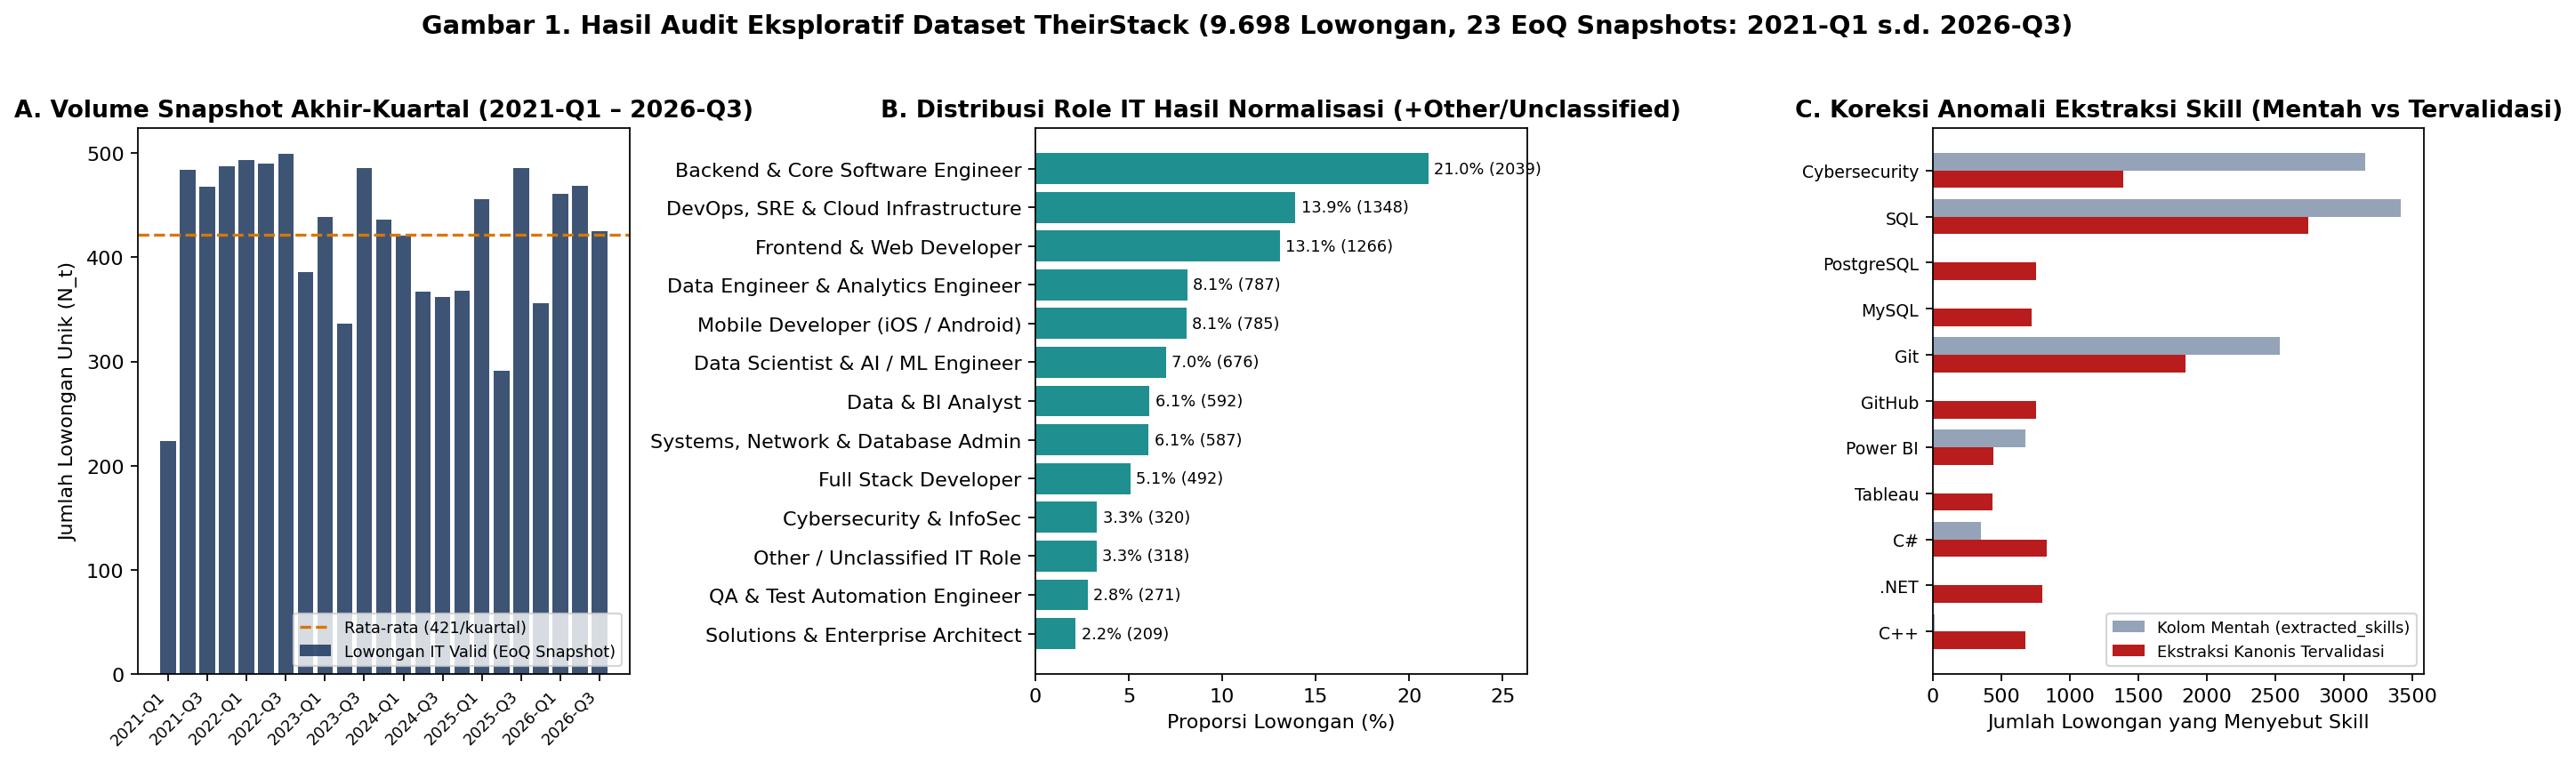

In [5]:
quarterly_audit_df = audit_tables["quarterly_audit_df"]
role_dist_df = audit_tables["role_dist_df"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
q_x = np.arange(len(quarterly_audit_df))
axes[0].bar(q_x, quarterly_audit_df["clean_valid_postings"], color="#1B365D", alpha=0.85, label="Lowongan IT Valid (EoQ Snapshot)")
axes[0].axhline(quarterly_audit_df["clean_valid_postings"].mean(), color="#D97706", linestyle="--", linewidth=1.5, label=f"Rata-rata ({quarterly_audit_df['clean_valid_postings'].mean():.0f}/kuartal)")
axes[0].set_xticks(q_x[::2])
axes[0].set_xticklabels(quarterly_audit_df["year_quarter"].iloc[::2], rotation=45, ha="right", fontsize=8)
axes[0].set_title("A. Volume Snapshot Akhir-Kuartal (2021-Q1 – 2026-Q3)", fontweight="bold")
axes[0].set_ylabel("Jumlah Lowongan Unik (N_t)")
axes[0].legend(loc="lower right", fontsize=8)

clean_roles = role_dist_df[role_dist_df["source"].str.startswith("Normalized")].sort_values("job_count", ascending=True)
axes[1].barh(clean_roles["role_name"], clean_roles["share_pct"], color="#008080", alpha=0.88)
for i, (_, r) in enumerate(clean_roles.iterrows()):
    axes[1].text(r["share_pct"] + 0.3, i, f"{r['share_pct']:.1f}% ({int(r['job_count'])})", va="center", fontsize=8)
axes[1].set_xlim(0, max(clean_roles["share_pct"]) * 1.25)
axes[1].set_title("B. Distribusi Role IT Hasil Normalisasi (+Other/Unclassified)", fontweight="bold")
axes[1].set_xlabel("Proporsi Lowongan (%)")

key_audit_skills = ["Cybersecurity", "SQL", "PostgreSQL", "MySQL", "Git", "GitHub", "Power BI", "Tableau", "C#", ".NET", "C++"]
sub_sk = skill_comparison_df[skill_comparison_df["skill"].isin(key_audit_skills)].set_index("skill").reindex(key_audit_skills).reset_index()
y_pos = np.arange(len(sub_sk))
axes[2].barh(y_pos - 0.19, sub_sk["raw_extracted_count"], height=0.38, color="#94A3B8", label="Kolom Mentah (extracted_skills)")
axes[2].barh(y_pos + 0.19, sub_sk["audited_canonical_count"], height=0.38, color="#B91C1C", label="Ekstraksi Kanonis Tervalidasi")
axes[2].set_yticks(y_pos)
axes[2].set_yticklabels(sub_sk["skill"], fontsize=8.5)
axes[2].invert_yaxis()
axes[2].set_title("C. Koreksi Anomali Ekstraksi Skill (Mentah vs Tervalidasi)", fontweight="bold")
axes[2].set_xlabel("Jumlah Lowongan yang Menyebut Skill")
axes[2].legend(loc="lower right", fontsize=8)
fig.suptitle("Gambar 1. Hasil Audit Eksploratif Dataset TheirStack (9.698 Lowongan, 23 EoQ Snapshots: 2021-Q1 s.d. 2026-Q3)", fontsize=13, fontweight="bold", y=1.02)
fig.tight_layout()
cfg.figures_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(cfg.figures_dir / "fig1_dataset_audit_and_skill_cleaning.png", dpi=220, bbox_inches="tight")
plt.show()
